### Modul 3: Feature Engineering dan EDA (Exploratory Data Analysis)

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import OrdinalEncoder, LabelEncoder
from sklearn.ensemble import RandomForestClassifier

In [ ]:
df = sns.load_dataset('penguins')
display(df.head())
print(df.info())

#### Menangani nilai hilang (missing values)

In [ ]:
df = df.dropna()
print(df.info())

#### Encoding data kategorikal

In [ ]:
# kolom sex memiliki dua kategori -> cocok untuk label encoder
le = LabelEncoder()
df['sex_encoded'] = le.fit_transform(df['sex'])
display(df[['sex', 'sex_encoded']].head())


# kolom island merupakan fitur nominal -> cocok untuk one hot encoding
island_one_hot = pd.get_dummies(df['island'], prefix='island')
df = df.join(island_one_hot)
display(df.head())

# ordinal encoding -> demonstrasi ranking spesies penguin berdasarkan massa tubuh
avg_mass = df.groupby('species')['body_mass_g'].mean().sort_values()
print(avg_mass)

species_order = avg_mass.index.tolist()
ordinal_encoder = OrdinalEncoder(categories=[species_order])
df['species_ordinal'] = ordinal_encoder.fit_transform(df[['species']])
display(df[['species', 'species_ordinal']].sample(10))

In [ ]:
display(df.head())
display(df.describe())

#### Binning (discretization)
mengelompokkan fitur numerik kedalam beberapa kategori

In [ ]:
# mengelompokkan massa tubuh penguin menjadi beberapa kategori (bins)
bins = [2500, 4000, 5000, 6000, 7000]
labels = ['light', 'medium', 'heavy', 'monster']

df['weight_category'] = pd.cut(df['body_mass_g'], bins=bins, labels=labels) # alt: pd.qcut
display(df[['species', 'body_mass_g', 'weight_category']].sample(10))
print(df['weight_category'].value_counts())

print(df.info())

### Feature selection
analisis korelasi, mengukur kekuatan hubungan linear antar variabel numerik

In [ ]:
correlation_matrix = df.corr(numeric_only=True)
plt.figure(figsize=(12, 10))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Correlation Matrix")
plt.show()

### Exploratory Data Analysis

In [ ]:
# analisis univariat -> analisis setiap fitur
print("Frekuensi spesies: ", df['species'].value_counts())
print("\nFrekuensi pulau: ", df['island'].value_counts())
print("\nFrekuensi jenis kelamin: ", df['sex'].value_counts())

display(df[['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']].describe())

Frekuensi spesies:  species
Adelie       146
Gentoo       119
Chinstrap     68
Name: count, dtype: int64

Frekuensi pulau:  island
Biscoe       163
Dream        123
Torgersen     47
Name: count, dtype: int64

Frekuensi jenis kelamin:  sex
Male      168
Female    165
Name: count, dtype: int64


,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
count,333.000000,333.000000,333.000000,333.000000
mean,43.992793,17.164865,200.966967,4207.057057
std,5.468668,1.969235,14.015765,805.215802
min,32.100000,13.100000,172.000000,2700.000000
25%,39.500000,15.600000,190.000000,3550.000000
50%,44.500000,17.300000,197.000000,4050.000000
75%,48.600000,18.700000,213.000000,4775.000000
max,59.600000,21.500000,231.000000,6300.000000


In [ ]:
# analisis bivariat -> analisis hubungan antar fitur
summary_stats = df.groupby('species')[['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']].agg(['mean', 'min', 'max'])
display(summary_stats)

# summary_stats = df.groupby('species').agg({
#     'bill_length_mm': ['mean', 'min', 'max'],
#     'bill_depth_mm': ['mean', 'min', 'max'],
#     'flipper_length_mm': ['mean', 'min', 'max'],
#     'body_mass_g': ['mean', 'min', 'max']
# })
# display(summary_stats)

bill_length_mm             bill_depth_mm              \
                    mean   min   max          mean   min   max   
species                                                          
Adelie         38.823973  32.1  46.0     18.347260  15.5  21.5   
Chinstrap      48.833824  40.9  58.0     18.420588  16.4  20.8   
Gentoo         47.568067  40.9  59.6     14.996639  13.1  17.3   

          flipper_length_mm                body_mass_g                  
                       mean    min    max         mean     min     max  
species                                                                 
Adelie           190.102740  172.0  210.0  3706.164384  2850.0  4775.0  
Chinstrap        195.823529  178.0  212.0  3733.088235  2700.0  4800.0  
Gentoo           217.235294  203.0  231.0  5092.436975  3950.0  6300.0

bill_length_mm             bill_depth_mm              \
                    mean   min   max          mean   min   max   
species                                                          
Adelie         38.823973  32.1  46.0     18.347260  15.5  21.5   
Chinstrap      48.833824  40.9  58.0     18.420588  16.4  20.8   
Gentoo         47.568067  40.9  59.6     14.996639  13.1  17.3   

          flipper_length_mm                body_mass_g                  
                       mean    min    max         mean     min     max  
species                                                                 
Adelie           190.102740  172.0  210.0  3706.164384  2850.0  4775.0  
Chinstrap        195.823529  178.0  212.0  3733.088235  2700.0  4800.0  
Gentoo           217.235294  203.0  231.0  5092.436975  3950.0  6300.0

In [73]:
# agregasi multi-level
multi_level_summary = df.groupby(['island', 'species'])['body_mass_g'].mean()
print(multi_level_summary)

island     species  
Biscoe     Adelie       3709.659091
           Gentoo       5092.436975
Dream      Adelie       3701.363636
           Chinstrap    3733.088235
Torgersen  Adelie       3708.510638
Name: body_mass_g, dtype: float64


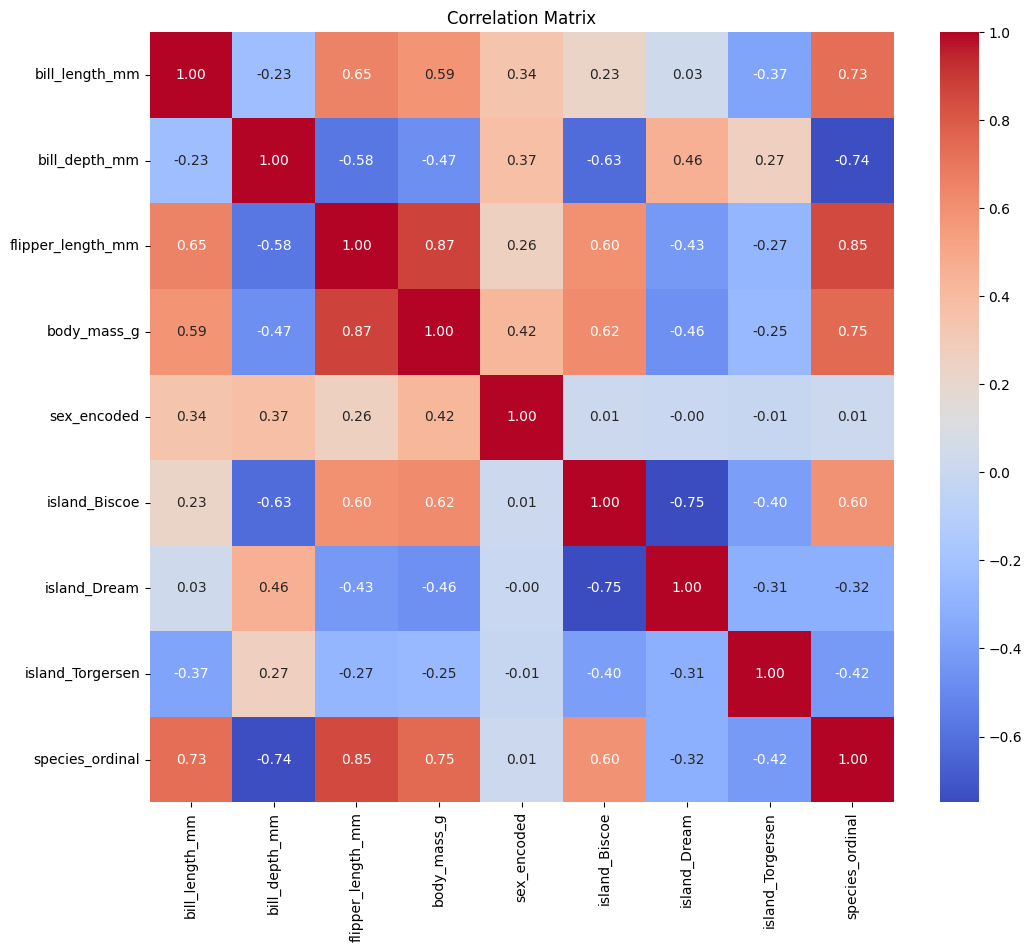

In [75]:
# analisis korelari
correlation_matrix = df.corr(numeric_only=True)
plt.figure(figsize=(12, 10))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Correlation Matrix")
plt.show()